In [1]:
#Block 1: Load and clean

In [2]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_excel("0day _In the Wild_.xlsx", sheet_name="All")
df = df[df["CVE"].str.startswith("CVE-", na=False)].copy()
df["Vendor"] = df["Vendor"].str.strip().replace({"TrendMicro": "Trend Micro", "Facebook": "Meta"})

print(len(df), "CVEs")
df.head()

410 CVEs


,CVE,Vendor,Product,Type,Description,Date Discovered,Date Patched,Advisory,Analysis URL,Root Cause Analysis,Reported By,Unnamed: 11
0,CVE-2026-85880,Microsoft,Windows,Memory Corruption,Windows Heap-Based Buffer Overflow Vulnerability,???,2026-09-09,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,"Volexity & Mark Kelly, David Galazin and Jerem...",NaN
1,CVE-2026-87491,Google,Chrome,Memory Corruption,V8 Out of Bounds Write Vulnerability,???,2026-09-08,https://chromereleases.googleblog.com/2026/09/...,???,NaN,"Jihyeon Jeong (Compsec Lab, Seoul National Uni...",NaN
2,CVE-2026-85046,Google,Chrome,Memory Corruption,Type confusion in V8,???,2026-09-03,https://chromereleases.googleblog.com/2026/09/...,???,NaN,Salvatore Gulizia (nickname: Serotav),NaN
3,CVE-2026-68820,Microsoft,Windows,Memory Corruption,Windows Ancillary Function Driver for WinSock ...,???,2026-08-11,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,Moshe Marelus and David Driker with Checkpoint,NaN
4,CVE-2026-56155,Microsoft,Windows,Feature Bypass,ADFS Elevation of Privilege Vulnerability,???,2026-07-14,https://msrc.microsoft.com/update-guide/vulner...,???,NaN,Jeremy Kingston (DART) and Scott Clark (DART),NaN


In [3]:
#Block 2: Compute latency

In [4]:
start = pd.to_datetime(df["Date Discovered"], format="%Y-%m-%d", errors="coerce")
patch = pd.to_datetime(df["Date Patched"], errors="coerce")
df["latency"] = (patch - start).dt.days
df["year"] = start.dt.year

usable = df[df["latency"] >= 0].copy()
usable["year"] = usable["year"].astype(int)

print(len(usable), "of", len(df), "CVEs have a usable latency")
usable[["CVE", "Vendor", "Date Discovered", "Date Patched", "latency"]].head()

132 of 410 CVEs have a usable latency


,CVE,Vendor,Date Discovered,Date Patched,latency
52,CVE-2024-53197,Google,2024-11-20,2025-04-01,132.0
53,CVE-2024-53150,Google,2024-11-25,2025-04-01,127.0
64,CVE-2024-50302,Google,2024-10-29,2025-03-01,123.0
68,CVE-2024-53104,Google,2024-11-07,2025-02-01,86.0
76,CVE-2024-43047,Qualcomm,2024-07-29,2024-10-07,70.0


In [5]:
#Block 3: Descriptive statistics

In [6]:
lat = usable["latency"]

print(lat.describe().round(1))
print("90th percentile:", lat.quantile(0.90))
for days in (7, 30, 90):
    print(f"patched within {days} days: {(lat <= days).mean() * 100:.1f}%")

count    132.0
mean      34.2
std       81.8
min        1.0
25%        3.0
50%        9.0
75%       30.2
max      834.0
Name: latency, dtype: float64
90th percentile: 85.50000000000003
patched within 7 days: 48.5%
patched within 30 days: 75.0%
patched within 90 days: 90.2%


In [7]:
#Block 4: Normality check

Shapiro-Wilk: W = 0.371, p = 2.23e-21
skewness: 7.38


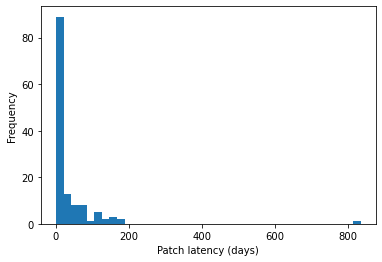

In [8]:
w, p = stats.shapiro(lat)
print(f"Shapiro-Wilk: W = {w:.3f}, p = {p:.2e}")
print(f"skewness: {stats.skew(lat):.2f}")

lat.plot.hist(bins=40)
plt.xlabel("Patch latency (days)")
plt.show()

In [9]:
#Block 5: RQ1, time trend

      count  median
year               
2015     16     9.0
2016     13    10.0
2017      2     9.0
2018      5    34.0
2019      5    10.0
2020     28    14.5
2021     24     6.0
2022     11     3.0
2023     18     9.0
2024     10    37.5
Spearman: rho = -0.043, p = 0.628
Kendall:  tau = -0.026, p = 0.680


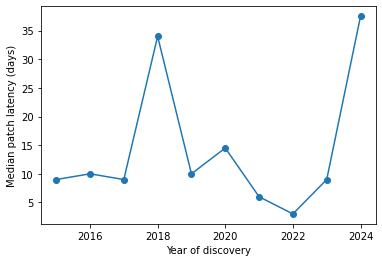

In [10]:
per_year = usable.groupby("year")["latency"].agg(["count", "median"])
print(per_year)

rho, p_rho = stats.spearmanr(usable["year"], usable["latency"])
tau, p_tau = stats.kendalltau(usable["year"], usable["latency"])
print(f"Spearman: rho = {rho:.3f}, p = {p_rho:.3f}")
print(f"Kendall:  tau = {tau:.3f}, p = {p_tau:.3f}")

per_year["median"].plot(marker="o")
plt.xlabel("Year of discovery")
plt.ylabel("Median patch latency (days)")
plt.savefig("median_latency_per_year.png", dpi=150)
plt.show()

In [11]:
#Block 6: RQ2, vendor comparison

In [12]:
from itertools import combinations

vendors = ["Microsoft", "Google", "Apple", "Adobe"]
top4 = usable[usable["Vendor"].isin(vendors)]
print(top4.groupby("Vendor")["latency"].describe().round(1))

groups = {v: top4.loc[top4["Vendor"] == v, "latency"] for v in vendors}
h, p = stats.kruskal(*groups.values())
print(f"\nKruskal-Wallis: H = {h:.2f}, p = {p:.2e}\n")

pairs = list(combinations(vendors, 2))
for a, b in pairs:
    p_pair = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided").pvalue
    print(f"{a} vs {b}: p = {p_pair:.2g}, adjusted p = {min(1, p_pair * len(pairs)):.2g}")

           count  mean   std  min   25%   50%   75%    max
Vendor                                                    
Adobe       14.0   8.2   7.8  1.0   4.2   6.0   8.5   29.0
Apple       10.0   9.0   1.4  6.0   9.0   9.5  10.0   10.0
Google      53.0  16.2  33.5  1.0   2.0   4.0   6.0  132.0
Microsoft   25.0  39.6  43.6  5.0  15.0  24.0  48.0  182.0

Kruskal-Wallis: H = 36.68, p = 5.37e-08

Microsoft vs Google: p = 2.8e-07, adjusted p = 1.7e-06
Microsoft vs Apple: p = 0.0002, adjusted p = 0.0012
Microsoft vs Adobe: p = 3.6e-05, adjusted p = 0.00021
Google vs Apple: p = 0.0045, adjusted p = 0.027
Google vs Adobe: p = 0.18, adjusted p = 1
Apple vs Adobe: p = 0.019, adjusted p = 0.12


In [13]:
#Block 7: Vendor box plot

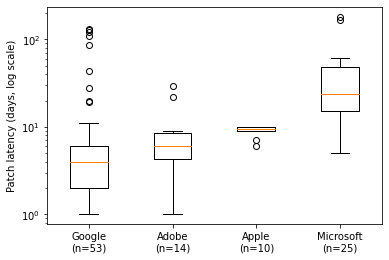

In [14]:
order = sorted(vendors, key=lambda v: groups[v].median())

plt.boxplot([groups[v] for v in order])
plt.xticks(range(1, len(order) + 1), [f"{v}\n(n={len(groups[v])})" for v in order])
plt.yscale("log")
plt.ylabel("Patch latency (days, log scale)")
plt.savefig("latency_by_vendor.png", dpi=150)
plt.show()

In [15]:
#Block 8: RQ3, product comparison

In [16]:
products = {
    "Microsoft": ["Windows", "Internet Explorer", "Office"],
    "Google": ["Chrome", "Android"],
    "Apple": ["iOS", "WebKit"],
}

for vendor, names in products.items():
    sub = usable[(usable["Vendor"] == vendor) & usable["Product"].isin(names)]
    print(sub.groupby("Product")["latency"].describe().round(1))
    samples = [sub.loc[sub["Product"] == name, "latency"] for name in names]
    if len(names) == 2:
        result = stats.mannwhitneyu(*samples, alternative="two-sided")
        print(f"{vendor}: Mann-Whitney U = {result.statistic:.1f}, p = {result.pvalue:.2g}\n")
    else:
        result = stats.kruskal(*samples)
        print(f"{vendor}: Kruskal-Wallis H = {result.statistic:.2f}, p = {result.pvalue:.2g}\n")

                   count  mean    std   min   25%   50%   75%    max
Product                                                             
Internet Explorer    3.0  65.3  101.1   5.0   7.0   9.0  95.5  182.0
Office               3.0  63.7   87.8  12.0  13.0  14.0  89.5  165.0
Windows             13.0  33.5   17.6  11.0  19.0  27.0  53.0   61.0
Microsoft: Kruskal-Wallis H = 1.06, p = 0.59

         count  mean   std   min   25%    50%    75%    max
Product                                                    
Android    6.0  97.8  46.1  10.0  91.8  116.0  126.0  132.0
Chrome    47.0   5.8   7.5   1.0   2.0    4.0    6.0   43.0
Google: Mann-Whitney U = 5.0, p = 0.00012

         count  mean  std  min  25%  50%   75%   max
Product                                             
WebKit     2.0   9.5  0.7  9.0  9.2  9.5   9.8  10.0
iOS        8.0   8.9  1.6  6.0  8.5  9.5  10.0  10.0
Apple: Mann-Whitney U = 7.0, p = 0.89



In [17]:
#Block 9: Reserved-date pull

In [18]:
import requests

BASE = "https://raw.githubusercontent.com/CVEProject/cvelistV5/main/cves"

def reserved_date(cve):
    _, year, number = cve.split("-")
    url = f"{BASE}/{year}/{number[:-3]}xxx/{cve}.json"
    response = requests.get(url, timeout=30)
    if response.status_code != 200:
        return None
    date = response.json()["cveMetadata"].get("dateReserved")
    return date[:10] if date else None

reserved = df["CVE"].apply(reserved_date)
print(reserved.notna().sum(), "of", len(df), "reserved dates found")
pd.DataFrame({"CVE": df["CVE"], "Date Reserved": reserved}).to_csv("reserved_dates.csv", index=False)

410 of 410 reserved dates found


In [19]:
#Block 10: Proxy validation

In [20]:
dates = pd.read_csv("reserved_dates.csv")
df["Date Reserved"] = df["CVE"].map(dates.set_index("CVE")["Date Reserved"])
reserved = pd.to_datetime(df["Date Reserved"])
df["latency_reserved"] = (patch - reserved).dt.days

gap = (start - reserved).dt.days.dropna()
print(len(gap), "CVEs have both dates")
print(f"mean absolute difference: {gap.abs().mean():.1f} days, SD: {gap.std():.1f}")
print(f"reserved before discovery: {(gap > 0).sum()}, same day: {(gap == 0).sum()}, after: {(gap < 0).sum()}")

rho_dates, _ = stats.spearmanr(start[gap.index].rank(), reserved[gap.index].rank())
both = df.dropna(subset=["latency", "latency_reserved"])
rho_latency, p_latency = stats.spearmanr(both["latency"], both["latency_reserved"])
print(f"Spearman between the two dates:     rho = {rho_dates:.3f}")
print(f"Spearman between the two latencies: rho = {rho_latency:.3f}, p = {p_latency:.2g}")

print(gap.groupby(df["Vendor"]).agg(["count", "median"]).loc[["Microsoft", "Google", "Apple", "Adobe"]])

133 CVEs have both dates
mean absolute difference: 55.7 days, SD: 88.3
reserved before discovery: 83, same day: 1, after: 49
Spearman between the two dates:     rho = 0.994
Spearman between the two latencies: rho = 0.438, p = 1.5e-07
           count  median
Vendor                  
Microsoft     25    79.0
Google        53     6.0
Apple         10     6.0
Adobe         14    31.0


In [21]:
#Block 11: Reserved-date dataset

In [22]:
res = df[df["latency_reserved"] >= 0].copy()
res["latency"] = res["latency_reserved"]
res["year"] = reserved.dt.year[res.index]

print(len(res), "of", len(df), "CVEs have a usable reserved-date latency")
print((df["latency_reserved"] < 0).sum(), "dropped because the ID was reserved after the patch")

lat_res = res["latency"]
print(lat_res.describe().round(1))
print("90th percentile:", lat_res.quantile(0.90))
for days in (7, 30, 90):
    print(f"patched within {days} days: {(lat_res <= days).mean() * 100:.1f}%")

w, p = stats.shapiro(lat_res)
print(f"Shapiro-Wilk: W = {w:.3f}, p = {p:.2e}")

403 of 410 CVEs have a usable reserved-date latency
6 dropped because the ID was reserved after the patch
count    403.0
mean      80.7
std       77.8
min        0.0
25%       23.5
50%       56.0
75%      114.5
max      426.0
Name: latency, dtype: float64
90th percentile: 186.0
patched within 7 days: 12.9%
patched within 30 days: 28.5%
patched within 90 days: 66.3%
Shapiro-Wilk: W = 0.855, p = 6.99e-19


In [23]:
#Block 12a: RQ1 on reserved dates

      count  median
year               
2013      1   235.0
2014     14    76.0
2015     31   116.0
2016     33   182.0
2017      7    41.0
2018     23   153.0
2019     16   102.5
2020     32    83.5
2021     57    46.0
2022     40    46.0
2023     50    33.0
2024     39    60.0
2025     46    40.0
2026     14     3.0
Spearman: rho = -0.440, p = 1.6e-20
Kendall:  tau = -0.312, p = 5e-19


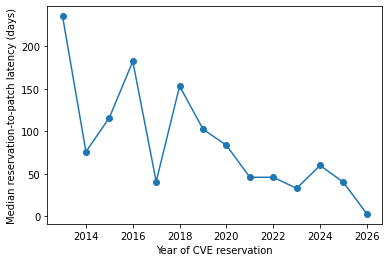

In [24]:
per_year_res = res.groupby("year")["latency"].agg(["count", "median"])
print(per_year_res)

rho, p_rho = stats.spearmanr(res["year"], res["latency"])
tau, p_tau = stats.kendalltau(res["year"], res["latency"])
print(f"Spearman: rho = {rho:.3f}, p = {p_rho:.2g}")
print(f"Kendall:  tau = {tau:.3f}, p = {p_tau:.2g}")

per_year_res["median"].plot(marker="o")
plt.xlabel("Year of CVE reservation")
plt.ylabel("Median reservation-to-patch latency (days)")
plt.savefig("median_latency_per_year_reserved.png", dpi=150)
plt.show()

In [25]:
#Block 12b: RQ1 check, same CVEs

In [26]:
same = res.loc[res.index.intersection(usable.index)]
checks = {
    "reservation-to-patch latency": same["latency"],
    "discovery-to-patch latency": usable.loc[same.index, "latency"],
    "days reserved before discovery": gap[same.index],
}
print(len(same), "CVEs with both dates")
for label, values in checks.items():
    rho, p = stats.spearmanr(same["year"], values)
    print(f"{label} vs year: rho = {rho:.3f}, p = {p:.2g}")

print(gap[same.index].groupby(same["year"]).agg(["count", "median"]))

130 CVEs with both dates
reservation-to-patch latency vs year: rho = -0.422, p = 5.6e-07
discovery-to-patch latency vs year: rho = 0.003, p = 0.97
days reserved before discovery vs year: rho = -0.552, p = 1e-11
      count  median
year               
2014      3    46.0
2015     16    38.0
2016     10    37.5
2017      2    74.0
2018      8   137.5
2019      4   101.0
2020     22    78.0
2021     25    43.0
2022     12    -2.0
2023     18    -2.0
2024     10    -1.5


In [27]:
#Block 13a: RQ2 on reserved dates

           count  mean   std  min   25%   50%    75%    max
Vendor                                                     
Adobe       28.0  65.9  58.6  5.0  17.2  52.5   95.0  235.0
Apple       64.0  59.7  56.2  4.0  15.8  46.5   91.0  244.0
Google      79.0  61.0  85.8  0.0   1.0  45.0   92.0  426.0
Microsoft  166.0  95.9  76.6  5.0  40.0  62.0  143.8  379.0
Kruskal-Wallis: H = 29.65, p = 1.64e-06
Microsoft vs Google: p = 5.6e-06, adjusted p = 3.4e-05
Microsoft vs Apple: p = 0.00011, adjusted p = 0.00065
Microsoft vs Adobe: p = 0.047, adjusted p = 0.28
Google vs Apple: p = 0.041, adjusted p = 0.25
Google vs Adobe: p = 0.074, adjusted p = 0.45
Apple vs Adobe: p = 0.6, adjusted p = 1


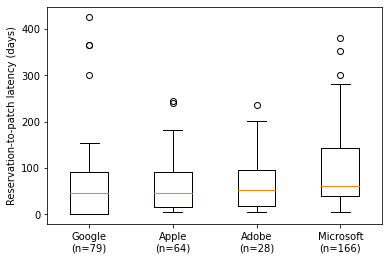

In [28]:
def compare(groups):
    h, p = stats.kruskal(*groups.values())
    print(f"Kruskal-Wallis: H = {h:.2f}, p = {p:.2e}")
    pairs = list(combinations(groups, 2))
    for a, b in pairs:
        p_pair = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided").pvalue
        print(f"{a} vs {b}: p = {p_pair:.2g}, adjusted p = {min(1, p_pair * len(pairs)):.2g}")

top4_res = res[res["Vendor"].isin(vendors)]
print(top4_res.groupby("Vendor")["latency"].describe().round(1))

groups_res = {v: top4_res.loc[top4_res["Vendor"] == v, "latency"] for v in vendors}
compare(groups_res)

order_res = sorted(vendors, key=lambda v: groups_res[v].median())
plt.boxplot([groups_res[v] for v in order_res])
plt.xticks(range(1, len(order_res) + 1), [f"{v}\n(n={len(groups_res[v])})" for v in order_res])
plt.ylabel("Reservation-to-patch latency (days)")
plt.savefig("latency_by_vendor_reserved.png", dpi=150)
plt.show()

In [29]:
#Block 13b: RQ2 check, 2022 onwards

In [30]:
recent = top4_res[top4_res["year"] >= 2022]
print(recent.groupby("Vendor")["latency"].describe().round(1))

groups_recent = {v: recent.loc[recent["Vendor"] == v, "latency"] for v in ["Microsoft", "Google", "Apple"]}
compare(groups_recent)

           count   mean    std   min   25%    50%    75%    max
Vendor                                                         
Adobe        2.0  107.5  133.6  13.0  60.2  107.5  154.8  202.0
Apple       42.0   47.7   43.5   4.0  16.0   40.0   69.0  240.0
Google      50.0   26.4   45.8   0.0   0.0    1.0   20.0  138.0
Microsoft   65.0   47.4   25.2   5.0  33.0   42.0   62.0  147.0
Kruskal-Wallis: H = 30.64, p = 2.22e-07
Microsoft vs Google: p = 5.8e-07, adjusted p = 1.8e-06
Microsoft vs Apple: p = 0.33, adjusted p = 0.98
Google vs Apple: p = 6.6e-06, adjusted p = 2e-05


In [31]:
#Block 14a: RQ3 on reserved dates

In [32]:
for vendor, names in products.items():
    sub = res[(res["Vendor"] == vendor) & res["Product"].isin(names)]
    print(sub.groupby("Product")["latency"].describe().round(1))
    compare({name: sub.loc[sub["Product"] == name, "latency"] for name in names})
    print()

                   count   mean   std   min   25%    50%    75%    max
Product                                                               
Internet Explorer   23.0  150.4  96.5  11.0  81.0  130.0  212.0  351.0
Office              18.0  103.3  76.4  27.0  42.0   66.0  162.8  242.0
Windows             98.0   89.1  72.0   5.0  40.0   60.0  131.5  379.0
Kruskal-Wallis: H = 7.91, p = 1.91e-02
Windows vs Internet Explorer: p = 0.0051, adjusted p = 0.015
Windows vs Office: p = 0.51, adjusted p = 1
Internet Explorer vs Office: p = 0.13, adjusted p = 0.4

         count   mean    std   min   25%    50%    75%    max
Product                                                      
Android   18.0  151.0  124.6  14.0  76.0  115.5  136.8  426.0
Chrome    61.0   34.5   45.1   0.0   0.0    3.0   71.0  153.0
Kruskal-Wallis: H = 22.81, p = 1.79e-06
Chrome vs Android: p = 1.8e-06, adjusted p = 1.8e-06

         count  mean   std  min   25%   50%    75%    max
Product                                     

In [33]:
#Block 14b: RQ3 check, Microsoft by period

In [34]:
ms = res[(res["Vendor"] == "Microsoft") & res["Product"].isin(products["Microsoft"])]
print(ms.groupby("Product")["year"].median())

early = ms[ms["year"] <= 2021]
print(early.groupby("Product")["latency"].agg(["count", "median"]))
compare({name: early.loc[early["Product"] == name, "latency"] for name in products["Microsoft"]})

Product
Internet Explorer    2016
Office               2016
Windows              2022
Name: year, dtype: int64
                   count  median
Product                         
Internet Explorer     22   141.0
Office                14   120.5
Windows               47   124.0
Kruskal-Wallis: H = 0.99, p = 6.09e-01
Windows vs Internet Explorer: p = 0.45, adjusted p = 1
Windows vs Office: p = 0.7, adjusted p = 1
Internet Explorer vs Office: p = 0.35, adjusted p = 1


In [35]:
#Block 15: CVSS pull

In [36]:
NVD = "https://raw.githubusercontent.com/fkie-cad/nvd-json-data-feeds/main"
session = requests.Session()

def cvss_score(cve):
    _, year, number = cve.split("-")
    url = f"{NVD}/CVE-{year}/CVE-{year}-{number[:-2]}xx/{cve}.json"
    response = session.get(url, timeout=30)
    if response.status_code != 200:
        return None, None
    metrics = response.json().get("metrics", {})
    entries = metrics.get("cvssMetricV31") or metrics.get("cvssMetricV30")
    if not entries:
        return None, None
    nist = [e for e in entries if e["source"] == "nvd@nist.gov"]
    chosen = (nist or entries)[0]
    return chosen["cvssData"]["baseScore"], "NVD" if nist else "other"

scores = pd.DataFrame(df["CVE"].apply(cvss_score).tolist(), columns=["CVSS", "CVSS Source"])
scores.insert(0, "CVE", df["CVE"].values)
print(scores["CVSS"].notna().sum(), "of", len(scores), "scores found")
print(scores["CVSS Source"].value_counts())
scores.to_csv("cvss_scores.csv", index=False)

410 of 410 scores found
NVD      313
other     97
Name: CVSS Source, dtype: int64


In [37]:
#Block 16a: RQ4, severity

In [38]:
scores = pd.read_csv("cvss_scores.csv").set_index("CVE")
band_names = ["Low", "Medium", "High", "Critical"]
severity = pd.cut(scores["CVSS"], bins=[0, 3.9, 6.9, 8.9, 10], labels=band_names).astype(str)
print(severity.value_counts()[band_names])

for name, data in [("Discovery dates", usable), ("Reserved dates", res)]:
    data["CVSS"] = data["CVE"].map(scores["CVSS"])
    data["Severity"] = data["CVE"].map(severity)
    print(f"\n{name}")
    print(data.groupby("Severity")["latency"].describe().round(1).reindex(band_names))
    compare({b: data.loc[data["Severity"] == b, "latency"] for b in ["Medium", "High", "Critical"]})
    rho, p = stats.spearmanr(data["CVSS"], data["latency"])
    print(f"Spearman, score vs latency: rho = {rho:.3f}, p = {p:.2g}")

Low           1
Medium       48
High        305
Critical     56
Name: CVSS, dtype: int64

Discovery dates
          count   mean    std   min   25%   50%    75%    max
Severity                                                     
Low         1.0   78.0    NaN  78.0  78.0  78.0   78.0   78.0
Medium     21.0  103.1  175.4   2.0  27.0  69.0  121.0  834.0
High       85.0   25.2   39.5   1.0   4.0   9.0   24.0  168.0
Critical   25.0    5.1    4.4   1.0   3.0   4.0    6.0   22.0
Kruskal-Wallis: H = 30.87, p = 1.98e-07
Medium vs High: p = 4.3e-05, adjusted p = 0.00013
Medium vs Critical: p = 4.6e-07, adjusted p = 1.4e-06
High vs Critical: p = 0.0017, adjusted p = 0.0051
Spearman, score vs latency: rho = -0.648, p = 4.4e-17

Reserved dates
          count  mean   std   min   25%   50%    75%    max
Severity                                                   
Low         1.0  39.0   NaN  39.0  39.0  39.0   39.0   39.0
Medium     47.0  84.3  72.3   0.0  40.0  60.0  107.0  364.0
High      300.0  8

In [39]:
for name, data in [("Discovery dates", usable), ("Reserved dates", res)]:
    print(f"\n{name}")
    for vendor in vendors:
        sub = data[data["Vendor"] == vendor]
        rho, p = stats.spearmanr(sub["CVSS"], sub["latency"])
        print(f"{vendor}: n = {len(sub)}, rho = {rho:.3f}, p = {p:.2g}")


Discovery dates
Microsoft: n = 25, rho = -0.521, p = 0.0076
Google: n = 53, rho = -0.524, p = 5.6e-05
Apple: n = 10, rho = 0.192, p = 0.59
Adobe: n = 14, rho = 0.032, p = 0.91

Reserved dates
Microsoft: n = 166, rho = -0.022, p = 0.78
Google: n = 79, rho = -0.396, p = 0.00031
Apple: n = 64, rho = -0.108, p = 0.39
Adobe: n = 28, rho = -0.084, p = 0.67
